# Week 4 — Baseline Model
**California Property Close Price Prediction**

> Deliverable: `03_baseline_model.ipynb` + recorded baseline metrics
>
> Handbook Week 4: train a **Linear Regression** as the first model, evaluate **R² on the test set**, record baseline results.
>
> This notebook consumes the **frozen Week 3 artifacts** in `output_week3/`:
> - `X_train_enc.npy` (105,974 × 41), `X_val_enc.npy` (11,416 × 41), `X_test_enc.npy` (12,339 × 41)
> - `y_train.npy`, `y_val.npy`, `y_test.npy` (ClosePrice in raw dollars)
> - test = 2026-04 (most recent month), val = 2026-03, train = 11 preceding months
> - features: 18 numeric (13 + 5 missing indicators) + 17 one-hot + 6 frequency-encoded, all standardized in Week 3
>
> Leakage guard: preprocessing was fit on train only in Week 3. Here the model is fit on **train only**; val is for a sanity look, and the test metrics are read **once, at the end** — test stays the unbiased referee for Weeks 5–7.


## 0. Setup — load the frozen Week 3 artifacts

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---- CONFIG: point to the Week 3 output folder (relative to where this notebook runs) ----
WEEK3_DIR = Path('output_week3')
OUT_DIR = Path('output_week4')
OUT_DIR.mkdir(exist_ok=True)

X_train = np.load(WEEK3_DIR / 'X_train_enc.npy'); y_train = np.load(WEEK3_DIR / 'y_train.npy')
X_val   = np.load(WEEK3_DIR / 'X_val_enc.npy');   y_val   = np.load(WEEK3_DIR / 'y_val.npy')
X_test  = np.load(WEEK3_DIR / 'X_test_enc.npy');  y_test  = np.load(WEEK3_DIR / 'y_test.npy')
features = pd.read_csv(WEEK3_DIR / 'feature_list.csv')['feature'].tolist()

# Consistency checks (row counts may vary slightly with your run; feature count must match)
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1] == len(features), 'Feature count mismatch'
assert len(y_train) == len(X_train) and len(y_val) == len(X_val) and len(y_test) == len(X_test), 'X/y length mismatch'
assert not np.isnan(X_train).any() and not np.isnan(X_test).any(), 'Unexpected NaNs in encoded features'

print('train:', X_train.shape, '| val:', X_val.shape, '| test:', X_test.shape)
print('features:', len(features))
med = tuple(f'${np.median(y):,.0f}' for y in (y_train, y_val, y_test))
print('price medians — train', med[0], '/ val', med[1], '/ test', med[2])


train: (105974, 41) | val: (11416, 41) | test: (12339, 41)
features: 41
price medians — train $884,000 / val $890,000 / test $915,000


## 1. Sanity anchors — naive baselines
Before fitting anything, two "dumb" predictors set the floor:
- **`median(train)`** — robust to the right skew of prices
- **`mean(train)`** — the constant that minimizes MSE

If a model can't beat the train median on the test set, something is wrong. R² here is measured against each split's own mean (that's what `r2_score` does), so a constant predictor scores ≤ 0.


In [2]:
def mape(y_true, y_pred):
    mask = y_true != 0
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)

def metrics(y_true, y_pred):
    return {
        'R2': float(r2_score(y_true, y_pred)),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'MAPE%': mape(y_true, y_pred),
    }

rows = []
def record(model, split, y_true, y_pred):
    rows.append({'model': model, 'split': split, **metrics(y_true, y_pred)})

train_median, train_mean = float(np.median(y_train)), float(np.mean(y_train))
for name, const in [('median(train)', train_median), ('mean(train)', train_mean)]:
    record(name, 'val', y_val, np.full(len(y_val), const))
    record(name, 'test', y_test, np.full(len(y_test), const))

def show(rows_):
    t = pd.DataFrame(rows_).set_index(['model', 'split'])
    f = t.copy()
    f['R2'] = f['R2'].map(lambda v: f'{v:.4f}')
    for c in ['RMSE', 'MAE']:
        f[c] = f[c].map(lambda v: f'${v:,.0f}')
    f['MAPE%'] = f['MAPE%'].map(lambda v: f'{v:.2f}%')
    return f

show(rows)


R2        RMSE       MAE   MAPE%
model         split                                       
median(train) val    -0.1090    $999,884  $586,649  49.67%
              test   -0.1247  $1,053,302  $614,448  49.72%
mean(train)   val    -0.0002    $949,572  $636,935  71.74%
              test   -0.0025    $994,470  $655,301  70.72%

## 2. Linear Regression — the baseline
`LinearRegression` has no hyperparameters (plain OLS, `fit_intercept=True`). Features are already standardized from Week 3, so coefficients are comparable in magnitude and optimization is stable.

**Fit on train only.** We record train/val/test metrics: the train–val gap hints at overfitting, and the val–test gap hints at temporal drift (test is the newest month, and medians crept up $884k → $890k → $915k).


In [3]:
lr = LinearRegression()
lr.fit(X_train, y_train)

pred_train = lr.predict(X_train)
pred_val = lr.predict(X_val)
pred_test = lr.predict(X_test)

record('LinearRegression', 'train', y_train, pred_train)
record('LinearRegression', 'val', y_val, pred_val)
record('LinearRegression', 'test', y_test, pred_test)

table = show(rows)
table


R2        RMSE       MAE   MAPE%
model            split                                       
median(train)    val    -0.1090    $999,884  $586,649  49.67%
                 test   -0.1247  $1,053,302  $614,448  49.72%
mean(train)      val    -0.0002    $949,572  $636,935  71.74%
                 test   -0.0025    $994,470  $655,301  70.72%
LinearRegression train   0.5548    $639,405  $403,621  40.50%
                 val     0.5447    $640,701  $411,319  40.75%
                 test    0.5569    $661,120  $419,225  40.68%

## 3. What the baseline learned — largest coefficients
Because Week 3 standardized the numeric features, the biggest |coefficients| are the features moving the predicted price most (in standardized units). One-hot / frequency-encoded columns are on different scales, so treat this as a rough read, not a ranking of "importance".


In [4]:
coef = pd.Series(lr.coef_, index=features).sort_values(key=np.abs, ascending=False)
print(f'intercept: ${lr.intercept_:,.0f}')
coef.head(10).map(lambda v: f'{v:+,.0f}')


intercept: $1,614,015


PostalCode                            -122,093,644
City                                    +1,498,086
HighSchoolDistrict                        -504,378
LivingArea                                +502,663
CountyOrParish                            +385,995
MLSAreaMajor                              +359,748
StateOrProvince_infrequent_sklearn        +288,459
StateOrProvince_CA                        -288,459
BathroomsTotalInteger                     +255,560
Levels_One                                +241,603
dtype: str

In [5]:
impact = pd.Series(np.abs(lr.coef_) * X_train.std(axis=0), index=features).sort_values(ascending=False)
print(impact.head(15).map(lambda v: f'${v:,.0f}'))
print()
print(impact.tail(10).map(lambda v: f'${v:,.0f}'))

LivingArea                       $502,663
BathroomsTotalInteger            $255,560
Latitude                         $239,757
YearBuilt                        $172,594
PostalCode                       $153,244
Longitude                        $142,472
Levels_One                       $115,646
Stories_was_missing              $114,975
BedroomsTotal                    $108,729
Stories                          $100,942
AssociationFee_was_missing        $98,613
MainLevelBedrooms_was_missing     $78,676
HighSchoolDistrict                $75,271
AssociationFee                    $69,482
Flooring                          $43,103
dtype: str

Levels_infrequent_sklearn             $4,543
GarageSpaces                          $4,082
MainLevelBedrooms                     $3,875
ParkingTotal                          $2,002
PoolPrivateYN_False                   $1,961
PoolPrivateYN_True                    $1,961
StateOrProvince_infrequent_sklearn    $1,772
StateOrProvince_CA                    $1,77

In [6]:
# --- Selection round 1: drop 8 negligible features -> 33 kept ---
drop = ['LotSizeSquareFeet', 'LotSizeSquareFeet_was_missing',
        'ParkingTotal',
        'PoolPrivateYN_False', 'PoolPrivateYN_True',
        'StateOrProvince_CA', 'StateOrProvince_infrequent_sklearn',
        'Levels_infrequent_sklearn']
keep_idx = [i for i, f in enumerate(features) if f not in drop]
print(f'dropped {len(drop)}, kept {len(keep_idx)}')

X_train_s, X_val_s, X_test_s = X_train[:, keep_idx], X_val[:, keep_idx], X_test[:, keep_idx]
lr_s = LinearRegression().fit(X_train_s, y_train)
for split, Xs, ys in [('train', X_train_s, y_train),
                      ('val', X_val_s, y_val),
                      ('test', X_test_s, y_test)]:
    record('LR_sel33', split, ys, lr_s.predict(Xs))

show(rows)

dropped 8, kept 33


R2        RMSE       MAE   MAPE%
model            split                                       
median(train)    val    -0.1090    $999,884  $586,649  49.67%
                 test   -0.1247  $1,053,302  $614,448  49.72%
mean(train)      val    -0.0002    $949,572  $636,935  71.74%
                 test   -0.0025    $994,470  $655,301  70.72%
LinearRegression train   0.5548    $639,405  $403,621  40.50%
                 val     0.5447    $640,701  $411,319  40.75%
                 test    0.5569    $661,120  $419,225  40.68%
LR_sel33         train   0.5547    $639,429  $403,624  40.49%
                 val     0.5447    $640,651  $411,319  40.76%
                 test    0.5570    $661,068  $419,194  40.67%

In [7]:
selected = [f for f in features if f not in drop]
pd.DataFrame({'feature': selected}).to_csv(OUT_DIR / 'selected_features.csv', index=False)
print(len(selected), 'features saved')

33 features saved


## 4. Diagnostics — where the baseline breaks
- **Actual vs predicted (test):** points should hug the diagonal; systematic bends mean the linear form is missing something (e.g., diminishing returns of living area).
- **Residuals vs predicted:** a funnel shape = heteroskedasticity (bigger errors on expensive homes — very common in housing).
- **Residual histogram:** roughly bell-shaped is good; heavy tails = a few listings the model badly misses.

Context for the drift: 30-yr mortgage rates hit ~7.28% in early Oct 2026 and price cuts hit their highest share since Oct 2022 (realtor.com, 2026-10-05). Our test month (2026-04) predates that, but the upward median drift across train → val → test already shows the market isn't stationary — expect the model to slightly underpredict if appreciation continued into April.


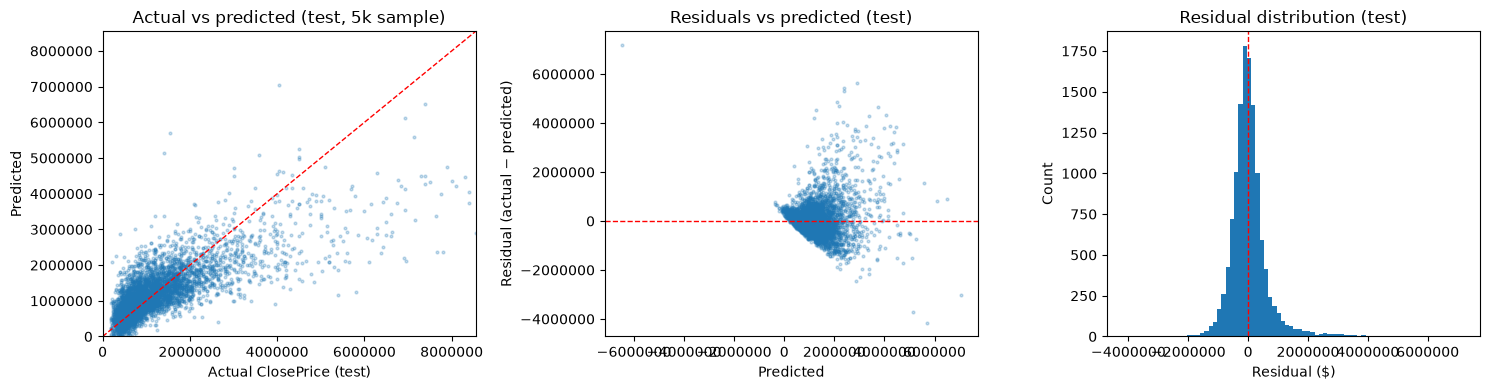

share of test predictions within ±10% of actual: 40.7%  (MAPE-style: 40.68%)
median residual (test): $-32,266  (negative = systematic overprediction)


In [9]:
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(y_test), size=min(5000, len(y_test)), replace=False)
yt, pt = y_test[idx], pred_test[idx]
resid = y_test - pred_test

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(yt, pt, s=4, alpha=0.25)
lim = [0, max(yt.max(), pt.max())]
axes[0].plot(lim, lim, 'r--', lw=1)
axes[0].set(xlabel='Actual ClosePrice (test)', ylabel='Predicted', title='Actual vs predicted (test, 5k sample)', xlim=lim, ylim=lim)

axes[1].scatter(pred_test[idx], resid[idx], s=4, alpha=0.25)
axes[1].axhline(0, color='r', ls='--', lw=1)
axes[1].set(xlabel='Predicted', ylabel='Residual (actual − predicted)', title='Residuals vs predicted (test)')

axes[2].hist(resid, bins=80)
axes[2].axvline(0, color='r', ls='--', lw=1)
axes[2].set(xlabel='Residual ($)', ylabel='Count', title='Residual distribution (test)')
for ax in axes: ax.ticklabel_format(style='plain', axis='both')

plt.tight_layout(); plt.show()

print(f"share of test predictions within ±10% of actual: {np.mean(np.abs(resid) / y_test) * 100:.1f}%  "
      f"(MAPE-style: {mape(y_test, pred_test):.2f}%)")
print(f'median residual (test): ${np.median(resid):+,.0f}  (negative = systematic overprediction)')



Diagnostic Findings (test set, n = 12,339)

Figure 1 — Actual vs predicted: accurate in the middle, breaks at the top. The linear form cannot reach the luxury segment — consistent with diminishing marginal returns to living area and luxury attributes (e.g., renovation quality, view tier) absent from the feature set.

Figure 2 — Residuals vs predicted: textbook heteroskedasticity. Residual spread fans out with predicted price (funnel shape). Absolute errors scale with price levels, as expected in housing data — the model is far less reliable for expensive homes.

Figure 3 — Residual distribution: near-symmetric with a heavy right tail. Roughly bell-shaped and centered near zero, but right-skewed, with the tail extending to +$6M. A small number of luxury listings are severely underpredicted. 

Median residual is −$32,266, indicating a slight systematic overprediction
Taken together, the model overpredicts ordinary homes and underpredicts luxury homes



## 5. Record baseline results
The handbook asks for the test R² and the recorded baseline. We save the full table (CSV + a human-readable summary) into `output_week4/` for the write-up. **Weeks 5–7 will compare against these exact numbers** — the test set itself should not be used for tuning.


In [10]:
full = pd.DataFrame(rows).set_index(['model', 'split']).round(4)
full.to_csv(OUT_DIR / 'baseline_metrics.csv')

test_r2 = full.loc[('LinearRegression', 'test'), 'R2']
lines = [
    'Week 4 — Linear Regression baseline (California close-price prediction)',
    f'Model: sklearn LinearRegression (OLS, fit_intercept=True), no hyperparameters',
    f'Train: {X_train.shape[0]:,} rows × {X_train.shape[1]} features (fit on train only)',
    f'Val:   {X_val.shape[0]:,} rows (2026-03, sanity look)',
    f'Test:  {X_test.shape[0]:,} rows (2026-04, evaluated once)',
    f'',
    f'>>> Test R2 (the baseline to beat): {test_r2:.4f}',
    f'    Test RMSE : ${full.loc[("LinearRegression", "test"), "RMSE"]:,.0f}',
    f'    Test MAE  : ${full.loc[("LinearRegression", "test"), "MAE"]:,.0f}',
    f'    Test MAPE : {full.loc[("LinearRegression", "test"), "MAPE%"]:.2f}%',
    f'',
    'Full table (incl. naive median/mean anchors):',
    full.to_string(),
]
(OUT_DIR / 'baseline_results.txt').write_text('\n'.join(lines))
print('\n'.join(lines))
print('\nSaved ->', OUT_DIR.resolve())


Week 4 — Linear Regression baseline (California close-price prediction)
Model: sklearn LinearRegression (OLS, fit_intercept=True), no hyperparameters
Train: 105,974 rows × 41 features (fit on train only)
Val:   11,416 rows (2026-03, sanity look)
Test:  12,339 rows (2026-04, evaluated once)

>>> Test R2 (the baseline to beat): 0.5569
    Test RMSE : $661,120
    Test MAE  : $419,225
    Test MAPE : 40.68%

Full table (incl. naive median/mean anchors):
                            R2          RMSE          MAE    MAPE%
model            split                                            
median(train)    val   -0.1090  9.998844e+05  586648.5004  49.6696
                 test  -0.1247  1.053302e+06  614448.2948  49.7170
mean(train)      val   -0.0002  9.495721e+05  636935.3992  71.7374
                 test  -0.0025  9.944697e+05  655301.2426  70.7161
LinearRegression train  0.5548  6.394048e+05  403621.2279  40.4969
                 val    0.5447  6.407014e+05  411319.3976  40.7535
         

## 6. Reading the baseline + what's next
- The **test R² above is the number Weeks 5–7 must beat**. 
- **train → val → test** R² path: a sharp drop at test (newest month) is temporal drift, not overfitting; a drop already at val is overfitting or a too-rigid linear form.
- Known limits of this baseline: it's linear in raw dollars while prices are right-skewed (a log-target variant is a classic follow-up, e.g., alongside Week 7's GBM tuning), and it has no interaction terms (bed/bath ratio, age — that's Week 6's feature engineering).
- **Week 5:** Decision Tree + Random Forest regressors; compare their **test R²** against the baseline recorded here. Do not re-tune on the test set — use val for any choices.


